# Exercise: RNN vs LSTM vs GRU on Text Classification

In this notebook you will build and compare three sequential models for **4-class text classification** on the AG News dataset.

Goals:

- implement a single model class that supports RNN, LSTM, and GRU
- train all three architectures and track performance
- select the best model and evaluate it on the test set

## Suggested Work Plan

1. Review the data pipeline — check vocabulary size and an example encoded sequence.
2. **TODO 1**: implement `Model.__init__` and `Model.forward` — choose the right recurrent layer and extract the final hidden state.
   Use the sanity-check cell to verify the output shape before training.
3. **TODO 2**: complete the training step inside the loop — forward pass, loss computation, and gradient update.
4. **TODO 3**: track which architecture achieves the highest validation accuracy.
5. Evaluate the selected model on the test set, then try the extensions at the end (homework).

## The AG News Dataset

AG News is a news topic classification benchmark collected from 2,000+ news sources.

| Property | Value |
|---|---|
| Task | 4-class text classification |
| Classes | World, Sports, Business, Sci/Tech |
| Train set | 120,000 articles (30,000 per class) |
| Test set | 7,600 articles (1,900 per class) |
| Input | Article title + description, concatenated |

We use a random subset of 5,000 training and 1,000 test examples to keep training fast during class.

Each item in the dataset is a dictionary with two fields:
- `"text"` — the article title and description
- `"label"` — an integer from 0 to 3 (World=0, Sports=1, Business=2, Sci/Tech=3)

In [1]:
# %pip install datasets

import re
from collections import Counter

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, random_split
from datasets import load_dataset
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

SEED = 42
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

/Users/filipa/Documents/GitHub/sib/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Using device: cpu


## Data pipeline

Same steps as in the lecture examples: standardize and tokenize → build a vocabulary from the **training** texts →
encode each text as a sequence of `max_len` integer indices (truncated or padded with 0).

In [2]:
dataset = load_dataset("fancyzhx/ag_news")
# random subsets (with a fixed seed): the original files may be ordered
train_data = list(dataset["train"].shuffle(seed=SEED).select(range(5000)))
test_data = list(dataset["test"].shuffle(seed=SEED).select(range(1000)))

class_names = ["World", "Sports", "Business", "Sci/Tech"]
num_epochs = 10
max_len = 25   # titles + descriptions are short: ~30-40 words

print(train_data[0])
print("Train class counts:", Counter(item["label"] for item in train_data))

Generating train split:   0%|          | 0/120000 [00:00<?, ? examples/s]

Generating train split: 100%|██████████| 120000/120000 [00:00<00:00, 2209185.31 examples/s]

Generating test split:   0%|          | 0/7600 [00:00<?, ? examples/s]

Generating test split: 100%|██████████| 7600/7600 [00:00<00:00, 2407424.70 examples/s]

{'text': 'Bangladesh paralysed by strikes Opposition activists have brought many towns and cities in Bangladesh to a halt, the day after 18 people died in explosions at a political rally.', 'label': 0}
Train class counts: Counter({3: 1324, 1: 1273, 0: 1253, 2: 1150})


In [3]:
# --- Tokenization (same as examples-text-processing.ipynb) ---
def tokenize(text):
    text = text.lower()
    text = re.sub(r"<.*?>", " ", text)    # HTML tags -> space
    text = re.sub(r"[^a-z]", " ", text)   # punctuation, digits -> space
    return text.split()

# --- Train / validation split (before building the vocabulary) ---
train_size = int(0.8 * len(train_data))
val_size = len(train_data) - train_size
train_subset, val_subset = random_split(train_data, [train_size, val_size],
                                        generator=torch.Generator().manual_seed(SEED))

# --- Vocabulary: built from the training part only ---
counter = Counter()
for item in train_subset:
    counter.update(tokenize(item["text"]))

vocab = {"<pad>": 0, "<unk>": 1}
for i, (word, _) in enumerate(counter.most_common(10000), start=2):
    vocab[word] = i
print(f"Vocabulary size: {len(vocab)}")

# --- Encoding & padding ---
def encode(text):
    ids = [vocab.get(t, 1) for t in tokenize(text)]
    ids = ids[:max_len]
    ids += [0] * (max_len - len(ids))
    return torch.tensor(ids)

# collate is called by DataLoader to assemble a list of individual samples into a batch.
# Each sample here is a raw dict {"text": ..., "label": ...}, so we encode the text and
# stack everything into tensors — DataLoader cannot do this automatically for dicts.
def collate(batch):
    X = torch.stack([encode(item["text"]) for item in batch])
    y = torch.tensor([item["label"] for item in batch])
    return X, y

# --- DataLoaders ---
train_loader = DataLoader(train_subset, batch_size=32, shuffle=True, collate_fn=collate)
val_loader   = DataLoader(val_subset,   batch_size=32, shuffle=False, collate_fn=collate)
test_loader  = DataLoader(test_data,    batch_size=32, shuffle=False, collate_fn=collate)

print(f"Train: {train_size} | Val: {val_size} | Test: {len(test_data)}")
print(f"Example text:    {train_subset[0]['text'][:100]}")
print(f"Example encoded: {encode(train_subset[0]['text'])}")

Vocabulary size: 10002
Train: 4000 | Val: 1000 | Test: 1000
Example text:    Feds could sell off real estate, improve buying to save billions: Brison (Canadian Press) Canadian P
Example encoded: tensor([2294,   84,  496,   91,  436, 2791, 1658, 1203,    3, 1150, 3583, 6335,
         336,  301,  336,  301,  800, 1151,    2,  165,   99,   28,  398,   14,
        1090])


## Model Architecture

Implement a single `Model` class that supports **RNN**, **LSTM**, and **GRU** via a `model_type` argument.

All three follow the same pattern: embed tokens → recurrent layer → classify from the final hidden state.

Keep in mind:
- `nn.RNN` and `nn.GRU` return `(output, h_n)`; `nn.LSTM` returns `(output, (h_n, c_n))` — extract only `h_n`
- `h_n` has shape `(num_layers, batch, hidden_dim)` — use `h_n[-1]` for the last layer
- the dataset has **4 classes**: the output layer produces 4 logits; no softmax is needed, because `nn.CrossEntropyLoss` applies it internally

In [4]:
class Model(nn.Module):
    def __init__(self, model_type, vocab_size, embed_dim, hidden_dim, num_layers, dropout=0.2):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=0)
        self.dropout = nn.Dropout(dropout)   # applied to the embeddings

        # TODO 1: create self.rnn as nn.RNN, nn.LSTM, or nn.GRU based on model_type ("RNN", "LSTM" or "GRU")
        # parameters: input_size=embed_dim, hidden_size=hidden_dim, num_layers=num_layers, batch_first=True
        rnn_classes = {"RNN": nn.RNN, "LSTM": nn.LSTM, "GRU": nn.GRU}
        self.model_type = model_type
        self.rnn = rnn_classes[model_type](input_size=embed_dim, hidden_size=hidden_dim,
                                           num_layers=num_layers, batch_first=True)

        self.fc = nn.Linear(hidden_dim, 4)  # 4 AG News classes

    def forward(self, x):
        x = self.embedding(x)   # (B, L) → (B, L, embed_dim)
        x = self.dropout(x)

        # TODO 1 (cont.): pass x through self.rnn → get (output, h)
        # for LSTM, h is a tuple (hidden, cell) — extract just hidden
        # use h[-1] (last layer's hidden state) as input to self.fc
        _, h = self.rnn(x)
        if self.model_type == "LSTM":
            h = h[0]

        return self.fc(h[-1])   # (B, 4)

### Sanity check

Before training, pass one batch through each model type: the output must have shape `(batch_size, 4)`.
The parameter counts show the cost of the gates (an LSTM layer has 4 weight blocks, a GRU 3, a simple RNN 1).

In [5]:
X, y = next(iter(train_loader))
for model_type in ["RNN", "LSTM", "GRU"]:
    m = Model(model_type, vocab_size=len(vocab), embed_dim=128, hidden_dim=128, num_layers=2)
    n_rnn = sum(p.numel() for p in m.rnn.parameters())
    n_all = sum(p.numel() for p in m.parameters())
    print(f"{model_type:5s} output shape: {tuple(m(X).shape)} | "
          f"recurrent-layer parameters: {n_rnn:,} | total: {n_all:,}")

RNN   output shape: (32, 4) | recurrent-layer parameters: 66,048 | total: 1,346,820
LSTM  output shape: (32, 4) | recurrent-layer parameters: 264,192 | total: 1,544,964
GRU   output shape: (32, 4) | recurrent-layer parameters: 198,144 | total: 1,478,916


## Training Loop

For each epoch: one pass over the training data updating the weights, then an evaluation pass on the validation data
(no gradient updates). The training loss and accuracy are averaged over the batches of the epoch, while the weights are
still changing.

In [6]:
def train_model(model_type):
    torch.manual_seed(SEED)   # same initialisation conditions for every architecture
    model = Model(model_type, vocab_size=len(vocab), embed_dim=128, hidden_dim=128, num_layers=2).to(device)
    optimizer = optim.Adam(model.parameters(), lr=2e-3)
    criterion = nn.CrossEntropyLoss()
    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}

    for epoch in range(num_epochs):
        model.train()
        total_loss, correct, total = 0, 0, 0

        for X, y in train_loader:
            X, y = X.to(device), y.to(device)
            optimizer.zero_grad()
            # TODO 2: forward pass → compute loss → backward → optimizer step
            # store the model output in `out` and the loss in `loss` (they are used below)
            out = model(X)
            loss = criterion(out, y)
            loss.backward()
            optimizer.step()



            total_loss += loss.item()
            preds = out.argmax(1)
            correct += (preds == y).sum().item()
            total += y.size(0)

        # --- Validation ---
        model.eval()
        val_loss, val_correct, val_total = 0, 0, 0
        with torch.no_grad():
            for X, y in val_loader:
                X, y = X.to(device), y.to(device)
                out = model(X)
                val_loss += criterion(out, y).item()
                val_correct += (out.argmax(1) == y).sum().item()
                val_total += y.size(0)

        history["train_loss"].append(total_loss / len(train_loader))
        history["val_loss"].append(val_loss / len(val_loader))
        history["train_acc"].append(correct / total)
        history["val_acc"].append(val_correct / val_total)

        print(f"[{model_type}] Epoch {epoch+1:02d}/{num_epochs} | "
              f"train loss: {history['train_loss'][-1]:.4f} | train acc: {correct/total:.4f} | "
              f"val loss: {history['val_loss'][-1]:.4f} | val acc: {val_correct/val_total:.4f}")

    return model, history

## Compare All Three Models

We select the architecture with the highest validation accuracy **at the end of training**, because those are the weights
we keep and evaluate on the test set. (Keeping the weights of the best epoch — *early stopping* / checkpointing — will be
discussed in a later session.) The test set is used only once, for the selected model.

In [7]:
trained_models = {}
histories = {}
best_model_name = None
best_val_acc = 0

for model_type in ["RNN", "LSTM", "GRU"]:
    print(f"\n--- Training {model_type} ---")
    model, hist = train_model(model_type)
    trained_models[model_type] = model
    histories[model_type] = hist

    # TODO 3: if this model's final validation accuracy (hist["val_acc"][-1]) is higher than best_val_acc,
    # update best_val_acc and best_model_name
    if hist["val_acc"][-1] > best_val_acc:
        best_val_acc = hist["val_acc"][-1]
        best_model_name = model_type


print(f"\nBest model: {best_model_name} (val acc: {best_val_acc:.4f})")


--- Training RNN ---


[RNN] Epoch 01/10 | train loss: 1.3856 | train acc: 0.3018 | val loss: 1.3387 | val acc: 0.3530


[RNN] Epoch 02/10 | train loss: 1.2471 | train acc: 0.4333 | val loss: 1.2641 | val acc: 0.4120


[RNN] Epoch 03/10 | train loss: 1.1189 | train acc: 0.5230 | val loss: 1.2022 | val acc: 0.4310


[RNN] Epoch 04/10 | train loss: 0.9779 | train acc: 0.5972 | val loss: 1.2155 | val acc: 0.4770


[RNN] Epoch 05/10 | train loss: 0.8113 | train acc: 0.6845 | val loss: 1.1663 | val acc: 0.5280


... (21 outputs left out)

[GRU] Epoch 07/10 | train loss: 0.0766 | train acc: 0.9735 | val loss: 0.9752 | val acc: 0.7500


[GRU] Epoch 08/10 | train loss: 0.0559 | train acc: 0.9798 | val loss: 1.0738 | val acc: 0.7670


[GRU] Epoch 09/10 | train loss: 0.0574 | train acc: 0.9785 | val loss: 0.9804 | val acc: 0.7910


[GRU] Epoch 10/10 | train loss: 0.0438 | train acc: 0.9832 | val loss: 1.1324 | val acc: 0.7730

Best model: GRU (val acc: 0.7730)


## Plot Results

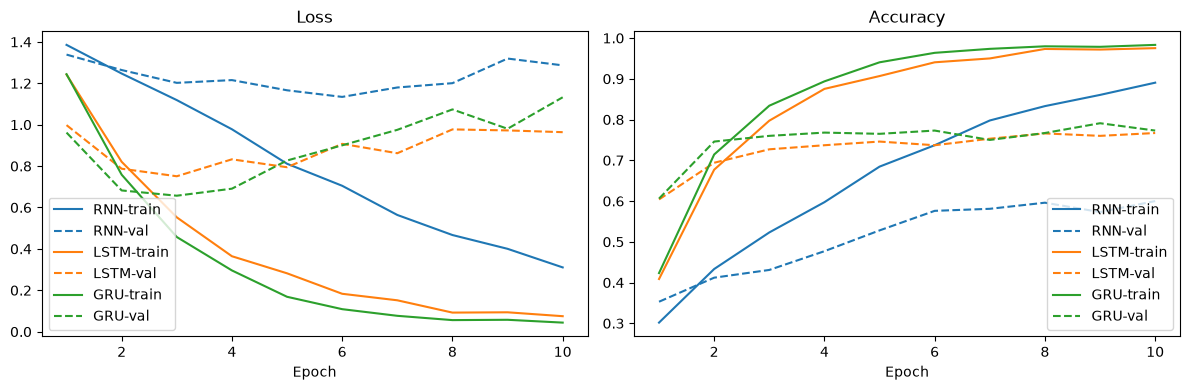

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
colors = {"RNN": "tab:blue", "LSTM": "tab:orange", "GRU": "tab:green"}

for m in ["RNN", "LSTM", "GRU"]:
    epochs = range(1, num_epochs + 1)
    axes[0].plot(epochs, histories[m]["train_loss"], color=colors[m], label=f"{m}-train")
    axes[0].plot(epochs, histories[m]["val_loss"], color=colors[m], linestyle="--", label=f"{m}-val")
    axes[1].plot(epochs, histories[m]["train_acc"], color=colors[m], label=f"{m}-train")
    axes[1].plot(epochs, histories[m]["val_acc"], color=colors[m], linestyle="--", label=f"{m}-val")

axes[0].set_title("Loss"); axes[0].set_xlabel("Epoch"); axes[0].legend()
axes[1].set_title("Accuracy"); axes[1].set_xlabel("Epoch"); axes[1].legend()
plt.tight_layout()
plt.show()

## Final Evaluation

Evaluate the best model on the test set and visualise results with a confusion matrix
(rows: true class, columns: predicted class).

Best model (GRU) — Test Accuracy: 0.7960


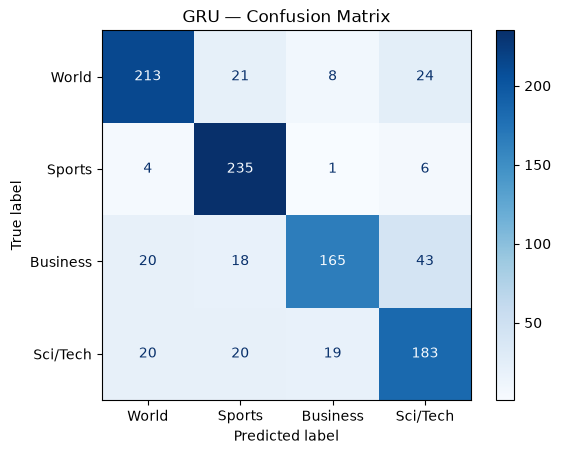

In [9]:
best_model = trained_models[best_model_name]
best_model.eval()
preds_all, labels_all = [], []

with torch.no_grad():
    for X, y in test_loader:
        X, y = X.to(device), y.to(device)
        preds = best_model(X).argmax(1)
        preds_all.extend(preds.cpu().numpy())
        labels_all.extend(y.cpu().numpy())

test_acc = np.mean(np.array(preds_all) == np.array(labels_all))
print(f"Best model ({best_model_name}) — Test Accuracy: {test_acc:.4f}")

cm = confusion_matrix(labels_all, preds_all)
ConfusionMatrixDisplay(cm, display_labels=class_names).plot(cmap="Blues")
plt.title(f"{best_model_name} — Confusion Matrix")
plt.show()

### Try it on new text

The model outputs 4 logits; `softmax` turns them into probabilities (only for display — training used the logits).

In [10]:
def predict(text, model=best_model):
    model.eval()
    with torch.no_grad():
        logits = model(encode(text).unsqueeze(0).to(device))   # (1, 4)
        probs = torch.softmax(logits, dim=1).squeeze(0).cpu()
    return {c: round(float(p), 3) for c, p in zip(class_names, probs)}

for headline in ["Stocks fall as oil prices rise to record high",
                 "Champions league: late goal gives the home team a dramatic win",
                 "New space telescope sends first images of distant galaxies",
                 "Peace talks resume after ceasefire in the region"]:
    print(headline, "->", predict(headline))

Stocks fall as oil prices rise to record high -> {'World': 0.0, 'Sports': 0.0, 'Business': 1.0, 'Sci/Tech': 0.0}
Champions league: late goal gives the home team a dramatic win -> {'World': 0.0, 'Sports': 1.0, 'Business': 0.0, 'Sci/Tech': 0.0}
New space telescope sends first images of distant galaxies -> {'World': 0.0, 'Sports': 0.0, 'Business': 0.0, 'Sci/Tech': 1.0}
Peace talks resume after ceasefire in the region -> {'World': 1.0, 'Sports': 0.0, 'Business': 0.0, 'Sci/Tech': 0.0}


## Questions and extensions (homework)

Questions:
1. Which classes are most often confused (see the confusion matrix)? Does it make sense?
2. Compare the train and validation curves of the three architectures. Do you see signs of overfitting?
3. How do the parameter counts relate to the results? Is the most complex model the best one?

Extensions (pick one or more):
- **Bidirectional**: add `bidirectional=True` to the recurrent layer; the classifier then receives
  `torch.cat([h[-2], h[-1]], dim=1)` (size `2 * hidden_dim`).
- **Sequence length**: change `max_len` (e.g. 15, 50). What happens to accuracy and training time?
- **Baseline**: train a bag-of-words or TF-IDF model (see `imdb_torch.ipynb`) on the same data. Do the recurrent models beat it?
- **Pretrained embeddings**: initialise the embedding layer with GloVe vectors (see `imdb_torch.ipynb`).
- **More data**: use 20,000 training examples instead of 5,000. Which architecture benefits most?

## Respostas

**1. Classes mais confundidas (matriz de confusão do GRU).** O maior erro é Business → Sci/Tech (43 notícias), seguido de World → Sci/Tech (24) e World → Sports (21). Faz sentido: notícias de empresas tecnológicas usam o vocabulário dos dois temas. Sports é a classe mais fácil (235 de 246 certas), com vocabulário muito próprio; Business é a mais difícil (165 de 246).

**2. Overfitting.** Existe nas três arquiteturas: a accuracy de treino chega a 0.89–0.98, a de validação fica em 0.60–0.77 e a loss de validação sobe nas últimas épocas.

**3. Complexidade.** O modelo com mais parâmetros (LSTM) não foi o melhor. O GRU, com cerca de 25% menos parâmetros, ficou ligeiramente à frente, mas a diferença (0.006 em 1000 exemplos) é pequena demais para concluir que é superior. A RNN simples é claramente pior.